In [1]:
import os
import json
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight

# =====================================================================
# 1. HARDWARE & DIRECTORY CONFIGURATION
# =====================================================================
BASE_DIR = r"D:\diavisosn"  # Update to your dataset root directory if different
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "val")
TEST_DIR = os.path.join(BASE_DIR, "test")

# EfficientNetB3 standard resolution is 300x300
IMG_SIZE = (300, 300)
BATCH_SIZE = 16
NUM_CLASSES = 2
AUTOTUNE = tf.data.AUTOTUNE

# Check GPU availability
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"Hardware Acceleration: GPU Detected ({len(gpus)} device(s))")
else:
    print("Running on CPU (Training may take longer).")

# =====================================================================
# 2. LOAD DATASETS VIA TF.DATA
# =====================================================================
print("\nLoading datasets...")

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

class_names = train_ds.class_names
print(f"Classes: {class_names}")

# Persist class indices to models/class_names.json
os.makedirs("models", exist_ok=True)
class_mapping = {cls: idx for idx, cls in enumerate(class_names)}
with open("models/class_names.json", "w") as f:
    json.dump(class_mapping, f, indent=4)
print("Saved models/class_names.json")

# =====================================================================
# 3. COMPUTE BALANCED CLASS WEIGHTS
# =====================================================================
# Extract training labels to handle class imbalance (eye: 1157, foot ulcer: 891)
train_labels = []
for _, labels in train_ds:
    train_labels.extend(np.argmax(labels.numpy(), axis=1))
train_labels = np.array(train_labels)

unique_classes = np.unique(train_labels)
computed_weights = compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=train_labels
)
class_weights = dict(zip(unique_classes, computed_weights))
print(f"Calculated Class Weights: {class_weights}")

# Optimize pipeline throughput
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# =====================================================================
# 4. BUILD MODEL ARCHITECTURE (EfficientNetB3)
# =====================================================================
# On-the-fly data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

def build_model(num_classes=2):
    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="input_image")
    x = data_augmentation(inputs)
    
    # EfficientNetB3 includes native normalization, so raw pixels [0, 255] are accepted
    base_model = tf.keras.applications.EfficientNetB3(
        include_top=False,
        weights="imagenet",
        input_tensor=x
    )
    
    # Freeze the base backbone for initial feature-head warmup
    base_model.trainable = False
    
    x = layers.GlobalAveragePooling2D(name="avg_pool")(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4, name="top_dropout")(x)
    x = layers.Dense(128, activation="relu", name="dense_features")(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name="DiaVision_EfficientNetB3")
    return model, base_model

model, base_backbone = build_model(num_classes=NUM_CLASSES)

# =====================================================================
# 5. COMPILE & PHASE 1 TRAINING (HEAD WARMUP)
# =====================================================================
metrics = [
    'accuracy',
    tf.keras.metrics.Precision(name='precision'),
    tf.keras.metrics.Recall(name='recall'),
    tf.keras.metrics.AUC(name='auc')
]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=metrics
)

checkpoint_path = "models/best_model.keras"
cb_list = [
    callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("\n--- PHASE 1: Training Classification Head ---")
history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=cb_list
)

# =====================================================================
# 6. PHASE 2: FINE-TUNING BACKBONE
# =====================================================================
print("\n--- PHASE 2: Fine-Tuning Top Convolutional Layers ---")
# Unfreeze top layers of the backbone
base_backbone.trainable = True
# Keep the first 300 layers frozen, tune the remaining deep layers
for layer in base_backbone.layers[:300]:
    layer.trainable = False

# Recompile with a significantly lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=metrics
)

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=cb_list
)

# =====================================================================
# 7. EVALUATION ON UNSEEN TEST SET
# =====================================================================
print("\n--- EVALUATING ON TEST SET ---")
best_model = tf.keras.models.load_model(checkpoint_path)
test_results = best_model.evaluate(test_ds, verbose=1)

print("\n" + "=" * 45)
print("FINAL TEST METRICS:")
print("-" * 45)
for metric_name, value in zip(best_model.metrics_names, test_results):
    print(f"{metric_name.upper():<15}: {value:.4f}")
print("=" * 45)
print(f"Model exported successfully to: {checkpoint_path}")

C:\anaconda\Lib\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.0)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


Running on CPU (Training may take longer).

Loading datasets...
Found 2045 files belonging to 2 classes.
Found 2043 files belonging to 2 classes.
Found 2043 files belonging to 2 classes.
Classes: ['eye', 'foot ulcer']
Saved models/class_names.json
Calculated Class Weights: {np.int64(0): np.float64(0.8837510803802938), np.int64(1): np.float64(1.1514639639639639)}

--- PHASE 1: Training Classification Head ---
Epoch 1/10


C:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9927 - auc: 0.9988 - loss: 0.0243 - precision: 0.9927 - recall: 0.9927  
Epoch 1: val_loss improved from None to 0.00035, saving model to models/best_model.keras

Epoch 1: finished saving model to models/best_model.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 417s 3s/step - accuracy: 0.9927 - auc: 0.9988 - loss: 0.0243 - precision: 0.9927 - recall: 0.9927 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 3.4857e-04 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0019 - precision: 0.9990 - recall: 0.9990      
Epoch 2: val_loss improved from 0.00035 to 0.00001, saving model to models/best_model.keras

Epoch 2: finished saving model to models/best_model.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 324s 3s/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0019 - precision: 0.9990 - recall: 0.9990 - val_accuracy: 1.0000 - val_auc: 1.0000 - va

Found 2043 files belonging to 2 classes.
128/128 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step


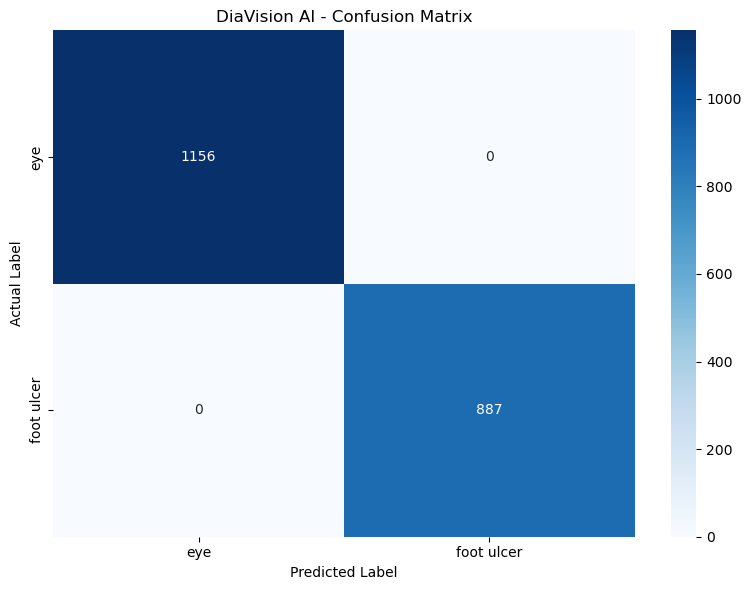

In [2]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

BASE_DIR = r"D:\diavisosn"
IMG_SIZE = (300, 300)
BATCH_SIZE = 16

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = test_ds.class_names

best_model = tf.keras.models.load_model(
    "models/best_model.keras"
)

y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for _, labels in test_ds
])

y_pred = np.argmax(
    best_model.predict(test_ds, verbose=1),
    axis=1
)

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("DiaVision AI - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [3]:
import os
import tensorflow as tf

SEARCH_DIR = r"D:\diavisosn"

for root, dirs, files in os.walk(SEARCH_DIR):
    for file in files:
        if file.endswith((".h5", ".hdf5")):
            print("Found:", os.path.join(root, file))

Found: D:\diavisosn\best_model.h5


In [5]:
import tensorflow as tf
import os

h5_path = r"D:\diavisosn\best_model.h5"
keras_path = r"D:\diavisosn\best_model.keras"

model = tf.keras.models.load_model(h5_path, compile=False)

model.save(keras_path)

print("Model converted successfully!")
print("Saved path:", keras_path)
print("File exists:", os.path.exists(keras_path))

Model converted successfully!
Saved path: D:\diavisosn\best_model.keras
File exists: True


C:\anaconda\Lib\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.0)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


Found 2043 files belonging to 2 classes.
Classes: ['eye', 'foot ulcer']
128/128 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step

========== OVERALL TEST RESULTS ==========
Accuracy          : 100.00%
Macro Precision   : 100.00%
Macro Recall      : 100.00%
Macro F1-Score    : 100.00%

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

         eye     1.0000    1.0000    1.0000      1156
  foot ulcer     1.0000    1.0000    1.0000       887

    accuracy                         1.0000      2043
   macro avg     1.0000    1.0000    1.0000      2043
weighted avg     1.0000    1.0000    1.0000      2043



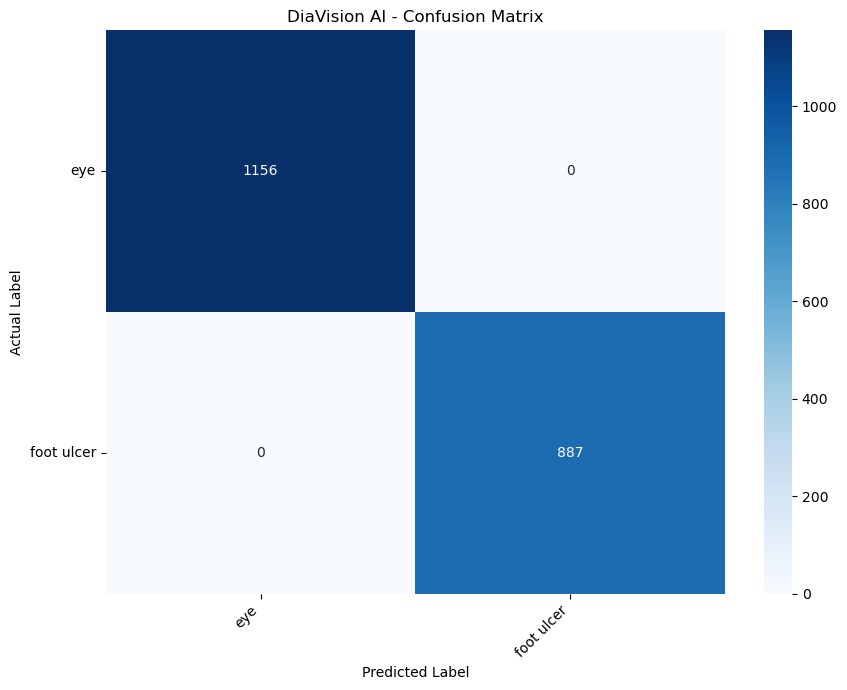


========== PER-CLASS METRICS TABLE ==========
            precision  recall  f1-score  support
eye               1.0     1.0       1.0   1156.0
foot ulcer        1.0     1.0       1.0    887.0


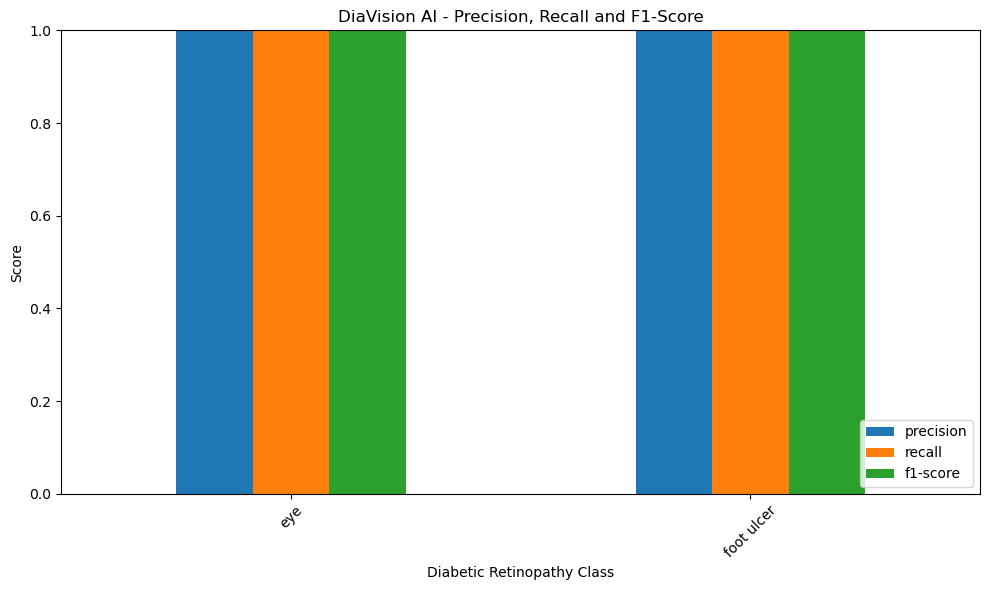


Classification metrics saved to:
diavision_classification_metrics.csv


In [3]:

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

BASE_DIR = r"D:\diavisosn"
IMG_SIZE = (300, 300)
BATCH_SIZE = 16

# 1. Load the test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = test_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)

# 2. Load the trained model
best_model = tf.keras.models.load_model(
    "models/best_model.keras"
)

# 3. Get actual labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for _, labels in test_ds
])

# 4. Predict class probabilities and predicted labels
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# 5. Calculate overall evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== OVERALL TEST RESULTS ==========")
print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Macro Precision   : {precision * 100:.2f}%")
print(f"Macro Recall      : {recall * 100:.2f}%")
print(f"Macro F1-Score    : {f1 * 100:.2f}%")

# 6. Classification report table
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print("\n========== CLASSIFICATION REPORT ==========")

# Print the formatted classification report
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# 7. Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("DiaVision AI - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 8. Precision, Recall and F1-score table
import pandas as pd

report_df = pd.DataFrame(report).transpose()

# Remove overall accuracy row from per-class table if desired
class_report_df = report_df.loc[class_names, [
    "precision", "recall", "f1-score", "support"
]]

print("\n========== PER-CLASS METRICS TABLE ==========")
print(class_report_df.round(4).to_string())

# 9. Plot precision, recall and F1-score for each class
metrics_df = class_report_df[
    ["precision", "recall", "f1-score"]
]

metrics_df.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=45
)

plt.title("DiaVision AI - Precision, Recall and F1-Score")
plt.xlabel("Diabetic Retinopathy Class")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 10. Save evaluation results
class_report_df.to_csv(
    "diavision_classification_metrics.csv"
)

print("\nClassification metrics saved to:")
print("diavision_classification_metrics.csv")
